<a href="https://colab.research.google.com/github/Hangsovoleak/Mathematics-for-Deep-Learning/blob/main/Mathematics_for_Deep_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install torch torchvision torchaudio

**Scalars**: 0th –order tensor (variables)
 contain number one at a time

In [ ]:
import torch
x = torch.tensor(3.0)
x

tensor(3.)

**Vectors**: 1st –order tensor (1st dimensional array)
 a fixed-length array of scalars

In [ ]:
x = torch.arange(3)
x

tensor([0, 1, 2])

**Metrics**: 2nd –order tensor (2nd dimensional array)
 contain row and column

**Tensors**: nth –order tensor
(nth dimensional array)

In [ ]:
A = torch.arange(6).reshape(3, 2)
A

tensor([[0, 1],
        [2, 3],
        [4, 5]])

**Calculus** is used for the **optimization problems** that we face in deep learning, where we repeatedly update our parameters in order to decrease the loss function.

1. **Derivatives**


*   a derivative is the rate of change in a function with respect to change in its arguments
*   derivatives can tell us how rapidly a loss function would increase or decrease were we to increase or decrease each parameter by an small amount.


2. **Gradients**


*   A derivative is used when a function has one variable.
*   A gradient is used when a function has multiple variables.


3. **Chain Rule**


*   Grandients of nested functions (of functions (of functions...)) is calculated through the chain rule.


### Ex1 (Discrete)

* **Experiment**: Toss a coin and record the side.
* **Random Variable $X$**:
  $$X = \begin{cases} 1 & \text{if Head} \\ 0 & \text{if Tail} \end{cases}$$
* Since $X \in \{0, 1\}$ is a countable set, $X$ is a **discrete random variable**.
* Probabilities:
  $$P(X = 1) = 0.5$$
  $$P(X = 0) = 0.5$$

In [ ]:
import torch

# Define the probability of getting heads (1)
p_heads = 0.5

# Simulate a single coin toss
single_toss = torch.bernoulli(torch.tensor([p_heads]))
print(f"Single coin toss result: {int(single_toss.item())} (1 = Heads, 0 = Tails)")

# Simulate 10 coin tosses
ten_tosses = torch.bernoulli(torch.full((10,), p_heads))
print(f"10 coin tosses: {ten_tosses.int().tolist()}")

# Calculate the percentage of heads over 10,000 trials
large_simulation = torch.bernoulli(torch.full((10000,), p_heads))
heads_ratio = large_simulation.mean().item()
print(f"Proportion of Heads in 10,000 tosses: {heads_ratio:.4f}")

Single coin toss result: 0 (1 = Heads, 0 = Tails)
10 coin tosses: [0, 0, 0, 0, 0, 1, 1, 1, 0, 1]
Proportion of Heads in 10,000 tosses: 0.4928


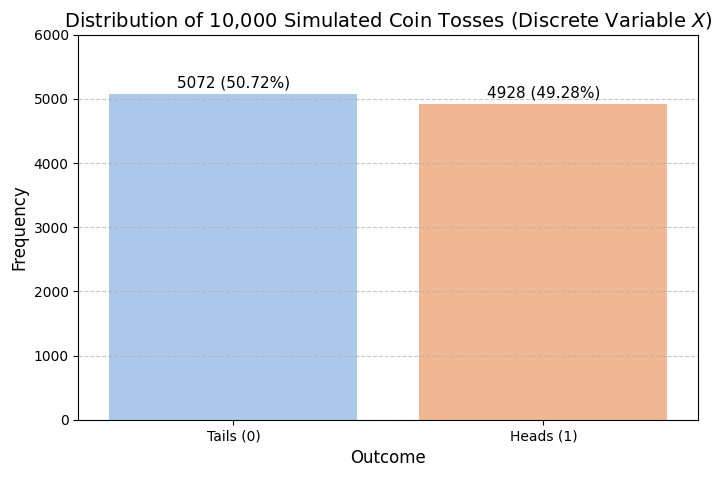

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Convert the 10,000 Bernoulli trials to a numpy array for analysis
tosses_np = large_simulation.numpy()

# Count occurrences of 0 (Tails) and 1 (Heads)
unique, counts = np.unique(tosses_np, return_counts=True)

plt.figure(figsize=(8, 5))
sns.barplot(x=['Tails (0)', 'Heads (1)'], y=counts, palette='pastel', hue=['Tails (0)', 'Heads (1)'], legend=False)

plt.title('Distribution of 10,000 Simulated Coin Tosses (Discrete Variable $X$)', fontsize=14)
plt.ylabel('Frequency', fontsize=12)
plt.xlabel('Outcome', fontsize=12)
plt.ylim(0, 6000)

# Annotate bars with the percentage
for i, count in enumerate(counts):
    percentage = (count / len(tosses_np)) * 100
    plt.text(i, count + 100, f"{count} ({percentage:.2f}%)", ha='center', fontsize=11)

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [ ]:
x = torch.arange(12, dtype=torch.float32)
x

tensor([ 0.,  1.,  2.,  3.,  4.,  5.,  6.,  7.,  8.,  9., 10., 11.])

### Ex2 (Continuous)

* **Experiment**: Randomly pick one person and measure his or her height, in meters.
* **Random Variable $Y$**: Let $Y$ denote the height of a selected person.
* Since we can measure the height with any precision, $Y$ takes a value from the uncountable set $Y \in (0, \infty)$, making it a **continuous random variable**.
* Human heights are typically modeled using a continuous **Normal (Gaussian) Distribution** with a mean (average height) and a standard deviation.

In [ ]:
import torch

# Let's model height using a normal distribution
# Suppose the average height is 1.75 meters with a standard deviation of 0.1 meters
mean_height = 1.75
std_dev = 0.1

# Simulate picking one random person's height
single_height = torch.normal(mean=torch.tensor([mean_height]), std=torch.tensor([std_dev]))
print(f"Single person's height: {single_height.item():.4f} meters")

# Simulate picking 10 random people
ten_heights = torch.normal(mean=torch.full((10,), mean_height), std=torch.full((10,), std_dev))
print(f"10 people's heights: {ten_heights.tolist()}")

# Simulate picking 10,000 people and calculate average height
large_sample = torch.normal(mean=torch.full((10000,), mean_height), std=torch.full((10000,), std_dev))
print(f"Average height in 10,000 samples: {large_sample.mean().item():.4f} meters")

Single person's height: 1.6888 meters
10 people's heights: [1.7548993825912476, 2.000535249710083, 1.5946881771087646, 1.695276141166687, 1.6528923511505127, 1.8960280418395996, 1.6932748556137085, 1.9417037963867188, 1.8948718309402466, 1.7094913721084595]
Average height in 10,000 samples: 1.7472 meters


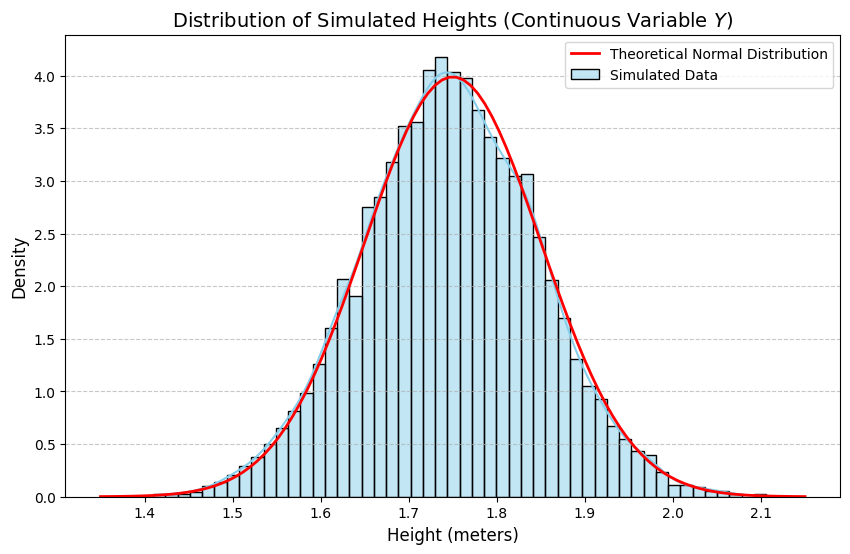

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import norm

# Convert the 10,000 samples to a numpy array for plotting
heights_np = large_sample.numpy()

# Set the figure size
plt.figure(figsize=(10, 6))

# Plot the distribution of simulated heights
sns.histplot(heights_np, bins=50, kde=True, stat='density', color='skyblue', label='Simulated Data')

# Plot the theoretical normal distribution curve
x_axis = np.linspace(mean_height - 4*std_dev, mean_height + 4*std_dev, 100)
plt.plot(x_axis, norm.pdf(x_axis, mean_height, std_dev), 'r-', lw=2, label='Theoretical Normal Distribution')

# Add details to the plot
plt.title('Distribution of Simulated Heights (Continuous Variable $Y$)', fontsize=14)
plt.xlabel('Height (meters)', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [ ]:
import numpy as np
b = np.array([5, 6, 7, 8])
b, type(b)


(array([5, 6, 7, 8]), numpy.ndarray)

In [ ]:
torch.ones((2, 3, 4))

tensor([[[1., 1., 1., 1.],
         [1., 1., 1., 1.],
         [1., 1., 1., 1.]],

        [[1., 1., 1., 1.],
         [1., 1., 1., 1.],
         [1., 1., 1., 1.]]])

In [ ]:
torch.randn(3, 4)

tensor([[-0.1491, -1.4499, -0.2003, -0.6255],
        [-0.7091,  0.4297, -0.6831, -1.2607],
        [-1.3498, -0.7707, -0.5383, -0.9385]])

In [ ]:
X = torch.arange(12, dtype=torch.float32).reshape((3, 4))
Y = torch.tensor([[2.0, 1, 4, 3], [1, 2, 3, 4], [4, 3, 2, 1]])

In [ ]:
X == Y

tensor([[False,  True, False,  True],
        [False, False, False, False],
        [False, False, False, False]])

In [ ]:
X.sum()

tensor(66.)

In [ ]:
a = torch.arange(3).reshape((3, 1))
b = torch.arange(2).reshape((1, 2))
a, b

(tensor([[0],
         [1],
         [2]]),
 tensor([[0, 1]]))

In [ ]:
a + b

tensor([[0, 1],
        [1, 2],
        [2, 3]])

In [ ]:
before = id(Y)
Y = Y + X
before, id(Y), id(Y) == before

(133145004306864, 133143407222992, False)

In [ ]:
Z = torch.zeros_like(Y)
print('id(Z):', id(Z))
Z[:] = X + Y
print('id(Z):', id(Z))

id(Z): 133143405755872
id(Z): 133143405755872


In [ ]:
before = id(X)
X += Y
id(X) == before

True

In [ ]:
# converting to NumPy
A = X.numpy()
B = torch.from_numpy(A)
type(A), type(B)

(numpy.ndarray, torch.Tensor)